In [5]:
# Import necessary libraries
from pyspark.sql import SparkSession

# 1. Initialize Spark Session (The core engine for this Big Data pipeline)
spark = SparkSession.builder \
    .appName("RetailNexus_Data_Ingestion") \
    .getOrCreate()

print("Spark Session Successfully Started!")

# 2. Ingest the dataset into the local environment/HDFS
dataset_path = "../DATA/ecommerce_clickstream_transactions.csv"
df_raw = spark.read.csv(dataset_path, header=True, inferSchema=True)

# 3. Verify that the data has been loaded correctly
print(f"Total Rows Ingested: {df_raw.count()}")
print("Raw Data Schema:")
df_raw.printSchema()

# Display the top 5 rows
df_raw.show(5)

Spark Session Successfully Started!
Total Rows Ingested: 74817
Raw Data Schema:
root
 |-- UserID: integer (nullable = true)
 |-- SessionID: integer (nullable = true)
 |-- Timestamp: timestamp (nullable = true)
 |-- EventType: string (nullable = true)
 |-- ProductID: string (nullable = true)
 |-- Amount: double (nullable = true)
 |-- Outcome: string (nullable = true)

+------+---------+--------------------+------------+---------+------+-------+
|UserID|SessionID|           Timestamp|   EventType|ProductID|Amount|Outcome|
+------+---------+--------------------+------------+---------+------+-------+
|     1|        1|2024-07-07 18:00:...|   page_view|     NULL|  NULL|   NULL|
|     1|        1|2024-03-05 22:01:...|   page_view|     NULL|  NULL|   NULL|
|     1|        1|2024-03-23 22:08:...|product_view|prod_8199|  NULL|   NULL|
|     1|        1|2024-03-12 00:32:...| add_to_cart|prod_4112|  NULL|   NULL|
|     1|        1|2024-02-25 22:43:...| add_to_cart|prod_3354|  NULL|   NULL|
+-----

In [6]:
from pyspark.sql.functions import col, hour, count, sum, desc

print("--- MODULE 2: DATA PROCESSING & ANALYTICS ---")

# 1. Data Cleaning: Remove duplicate records
df_cleaned = df_raw.dropDuplicates()
print(f"Rows after removing duplicates: {df_cleaned.count()}")

# Filter Sales Data (Keep only rows where a purchase was actually made, i.e., Amount is not NULL)
df_sales = df_cleaned.filter(col("Amount").isNotNull())

# KPI 1: Calculate Total Sales Revenue
total_sales = df_sales.select(sum("Amount")).collect()[0][0]
print(f"\n1. Total E-commerce Revenue: ${total_sales:,.2f}")

# KPI 2: Peak Buying Hours (Identify the times when users shop the most)
print("\n2. Peak Buying Hours:")
peak_hours = df_sales.withColumn("Hour", hour(col("Timestamp"))) \
    .groupBy("Hour") \
    .agg(count("SessionID").alias("Total_Transactions"), sum("Amount").alias("Revenue")) \
    .orderBy(desc("Total_Transactions"))
peak_hours.show(5)

# KPI 3: Top Performing Products (Identify products generating the highest revenue)
print("\n3. Top Performing Products:")
top_products = df_sales.groupBy("ProductID") \
    .agg(count("SessionID").alias("Units_Sold"), sum("Amount").alias("Total_Revenue")) \
    .orderBy(desc("Total_Revenue"))
top_products.show(5)

--- MODULE 2: DATA PROCESSING & ANALYTICS ---
Rows after removing duplicates: 74817

1. Total E-commerce Revenue: $2,704,573.00

2. Peak Buying Hours:
+----+------------------+------------------+
|Hour|Total_Transactions|           Revenue|
+----+------------------+------------------+
|  11|               478|118926.93250376554|
|   7|               473|122885.65662704389|
|   4|               472|122947.29624746913|
|  16|               467|115846.35616115134|
|   9|               466|115889.28312100076|
+----+------------------+------------------+
only showing top 5 rows


3. Top Performing Products:
+---------+----------+------------------+
|ProductID|Units_Sold|     Total_Revenue|
+---------+----------+------------------+
|prod_9747|         7|2163.8213511548083|
|prod_1342|         6| 2141.778214894626|
|prod_4270|         7| 1970.578638212547|
|prod_4114|         5|  1960.63291563733|
|prod_5908|         5|1948.3755143050325|
+---------+----------+------------------+
only showing

In [8]:
import os
print("--- MODULE 3: HIVE WAREHOUSING & DASHBOARD  ---")

# 1. Hive Warehousing: Convert the processed PySpark DataFrame into a temporary SQL View (simulating Apache Hive tables)
df_sales.createOrReplaceTempView("retail_hive_table")
print("SUCCESS: Data loaded into temporary SQL view 'retail_hive_table'.")

# 2. SQL Querying: Extract Daily Sales Trends using SQL for the dashboard's line chart
daily_trend = spark.sql("""
    SELECT DATE(Timestamp) as Sales_Date, SUM(Amount) as Daily_Revenue
    FROM retail_hive_table
    GROUP BY DATE(Timestamp)
    ORDER BY Sales_Date
""")

print("\nDaily Sales Trend (First 5 Days):")
daily_trend.show(5)

# 3. Dashboard Data Export: Define the directory to save CSV files for Power BI / Tableau
export_path = "../DATA/dashboard_exports"
os.makedirs(export_path, exist_ok=True)

# 4. Convert PySpark DataFrames to Pandas and save as single CSV files for easy dashboard importing
peak_hours.toPandas().to_csv(f"{export_path}/peak_hours.csv", index=False)
top_products.toPandas().to_csv(f"{export_path}/top_products.csv", index=False)
daily_trend.toPandas().to_csv(f"{export_path}/daily_trend.csv", index=False)

print(f"\nSUCCESS: All KPI datasets have been exported to the '{export_path}' directory.")
print("The data is now ready to be imported into Power BI or Tableau for interactive visualization.")

--- MODULE 3: HIVE WAREHOUSING & DASHBOARD  ---
SUCCESS: Data loaded into temporary SQL view 'retail_hive_table'.

Daily Sales Trend (First 5 Days):
+----------+------------------+
|Sales_Date|     Daily_Revenue|
+----------+------------------+
|2024-01-01|13135.520674553643|
|2024-01-02|  16436.9272825522|
|2024-01-03|11209.661465522227|
|2024-01-04|12885.815729059495|
|2024-01-05| 9051.293774702763|
+----------+------------------+
only showing top 5 rows


SUCCESS: All KPI datasets have been exported to the '../DATA/dashboard_exports' directory.
The data is now ready to be imported into Power BI or Tableau for interactive visualization.


--- MODULE 4: DATA VISUALIZATION (Python Dashboard) ---


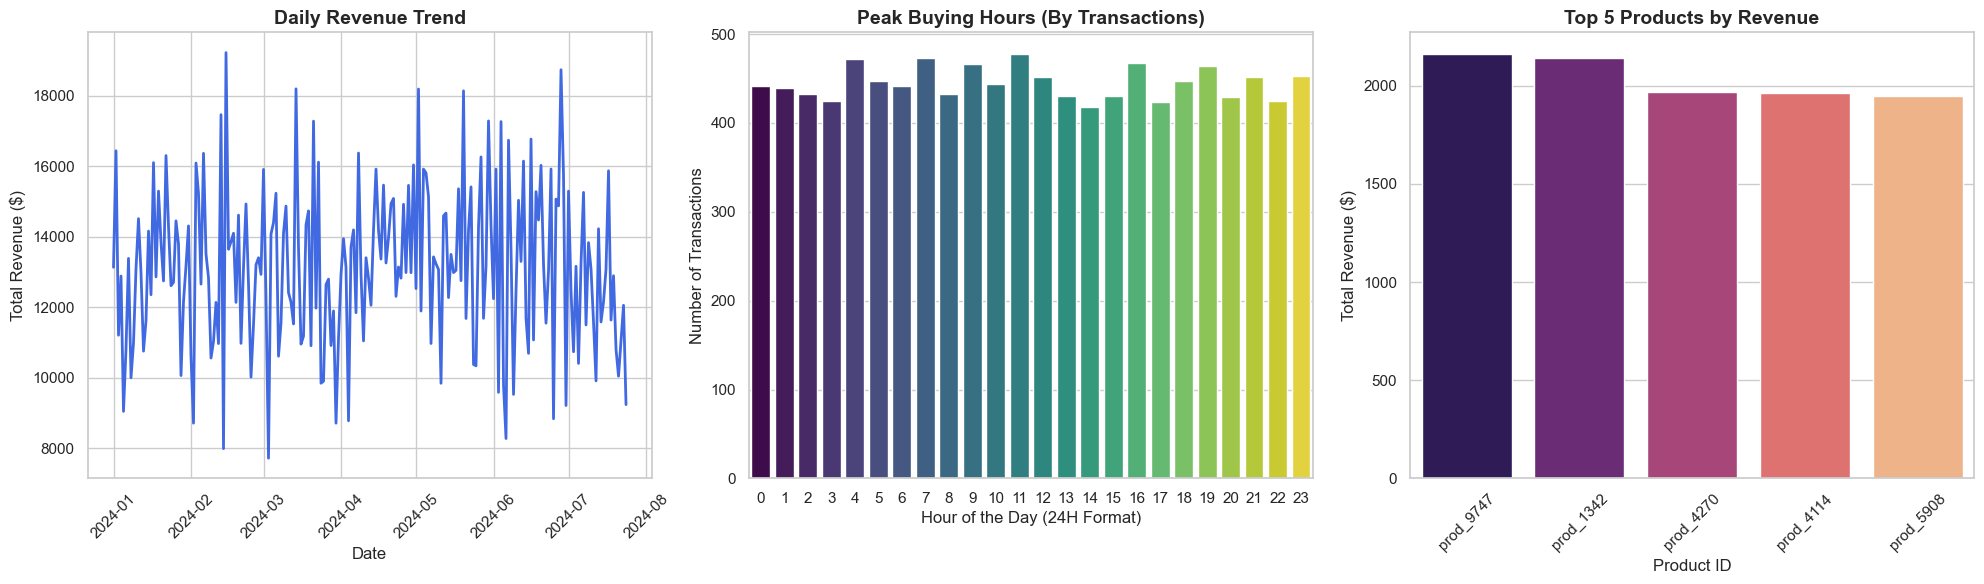

In [12]:
# Import visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

print("--- MODULE 4: DATA VISUALIZATION (Python Dashboard) ---")

# 1. Convert PySpark DataFrames to Pandas (Limiting products to Top 5)
pdf_daily = daily_trend.toPandas()
pdf_hours = peak_hours.toPandas()
pdf_products = top_products.limit(5).toPandas()  # Fix: Sirf top 5 products ko visualize karna hai

# 2. Set the visual style for the dashboard
sns.set_theme(style="whitegrid")
plt.figure(figsize=(20, 6))

# Chart A: Daily Sales Trend (Line Chart)
plt.subplot(1, 3, 1)
sns.lineplot(data=pdf_daily, x="Sales_Date", y="Daily_Revenue", color="royalblue", linewidth=2)
plt.title("Daily Revenue Trend", fontsize=14, fontweight="bold")
plt.xlabel("Date", fontsize=12)
plt.ylabel("Total Revenue ($)", fontsize=12)
plt.xticks(rotation=45)

# Chart B: Peak Buying Hours (Bar Chart)
plt.subplot(1, 3, 2)
# Fix: Added 'hue' and 'legend=False' to remove Seaborn warning
sns.barplot(data=pdf_hours, x="Hour", y="Total_Transactions", hue="Hour", palette="viridis", legend=False)
plt.title("Peak Buying Hours (By Transactions)", fontsize=14, fontweight="bold")
plt.xlabel("Hour of the Day (24H Format)", fontsize=12)
plt.ylabel("Number of Transactions", fontsize=12)

# Chart C: Top Performing Products (Bar Chart)
plt.subplot(1, 3, 3)
# Fix: Added 'hue' and 'legend=False' to remove Seaborn warning
sns.barplot(data=pdf_products, x="ProductID", y="Total_Revenue", hue="ProductID", palette="magma", legend=False)
plt.title("Top 5 Products by Revenue", fontsize=14, fontweight="bold")
plt.xlabel("Product ID", fontsize=12)
plt.ylabel("Total Revenue ($)", fontsize=12)
plt.xticks(rotation=45)

# 3. Adjust layout, SAVE as image, and render the dashboard
plt.tight_layout()

# Ye line dashboard ko ek high-quality PNG image ki tarah save karegi
plt.savefig("../DATA/dashboard_exports/dashboard_preview.png", dpi=300, bbox_inches="tight")

plt.show()